Import modules

In [1]:
from ntrfc.meshquality.nondimensionals import calc_dimensionless_gridspacing
import pyvista as pv
import numpy as np
import os


if os.getenv('DISPLAY') is None:
    pv.start_xvfb()  # Start X virtual framebuffer (Xvfb)


Define the box

In [2]:
height = 2
length =1
width = 1

def structured_testgrid(height, length, nodes, width):
    # define the mesh
    xrng = np.arange(0, nodes, 1, dtype=np.float32)
    yrng = np.arange(0, nodes, 1, dtype=np.float32)
    zrng = np.arange(0, nodes, 1, dtype=np.float32)
    x, y, z = np.meshgrid(xrng, yrng, zrng)
    grid = pv.StructuredGrid(x, y, z)
    # scale the mesh
    grid.points /= nodes - 1
    grid.points *= np.array([width, height, length])
    return grid

Define fluid properties

In [3]:
mu_0 = 1  # dynamic viscosity
rho = 1
velocity = 2
gradient = velocity / height

Lets generaate a mesh

In [4]:
nodes = 11
# needs to be something simple
mu_0 = 1  # dynamic viscosity
rho = 1
velocity = 2
gradient = velocity / height
# analytical solution_utils
span_x = width / (nodes - 1)
span_y = height / (nodes - 1)
span_z = length / (nodes - 1)
wallshearstress = mu_0 * gradient
wallshearvelocity = np.sqrt(wallshearstress / rho)
deltaxplus = wallshearvelocity * span_x / mu_0
deltayplus = wallshearvelocity * span_y / mu_0
deltazplus = wallshearvelocity * span_z / mu_0
grid = structured_testgrid(height, length, nodes, width)

# define velocityfield
bounds = grid.bounds
min_z = bounds[4]
grid["U"] = [gradient * (grid.cell_centers().points[::, 1][i] - min_z) * np.array([0, 0, 1]) for i in
             range(grid.number_of_cells)]
grid["rho"] = np.ones(grid.number_of_cells)
# extract surface
surface = grid.extract_surface()
facecellids = surface.surface_indices()
upperwallids = []
lowerwallids = []
for faceid in facecellids:
    cell = surface.extract_cells(faceid)
    if all(cell.points[::, 1] == 0):
        lowerwallids.append(faceid)
    elif all(cell.points[::, 1] == height):
        upperwallids.append(faceid)
lowerwall = surface.extract_cells(lowerwallids)
upperwall = surface.extract_cells(upperwallids)
lowerwall["U"] = [gradient * (lowerwall.cell_centers().points[::, 1][i] - min_z) * np.array([0, 0, 1]) for i in
                  range(lowerwall.number_of_cells)]
upperwall["U"] = [gradient * (upperwall.cell_centers().points[::, 1][i] - min_z) * np.array([0, 0, 1]) for i in
                  range(upperwall.number_of_cells)]
lowerwall["rho"] = np.ones(lowerwall.number_of_cells) * rho
upperwall["rho"] = np.ones(upperwall.number_of_cells) * rho

Lets define a solution

In [5]:
bounds = grid.bounds
min_z = bounds[4]
grid["U"] = [gradient * (grid.cell_centers().points[::,1][i]-min_z) * np.array([0,0,1]) for i in range(grid.number_of_cells)]
grid["rho"] = np.ones(grid.number_of_cells)

In [6]:
dimless_gridspacings = calc_dimensionless_gridspacing(grid, [lowerwall, upperwall], "U", "rho", mu_0)

constructing surfacemesh from wall meshes ...
calculating wall-normal vectors...
finding walladjacent cells
calculating cell spans from WallNormals...
calculating wall-shear and friction-velocity


visualize the velocity field

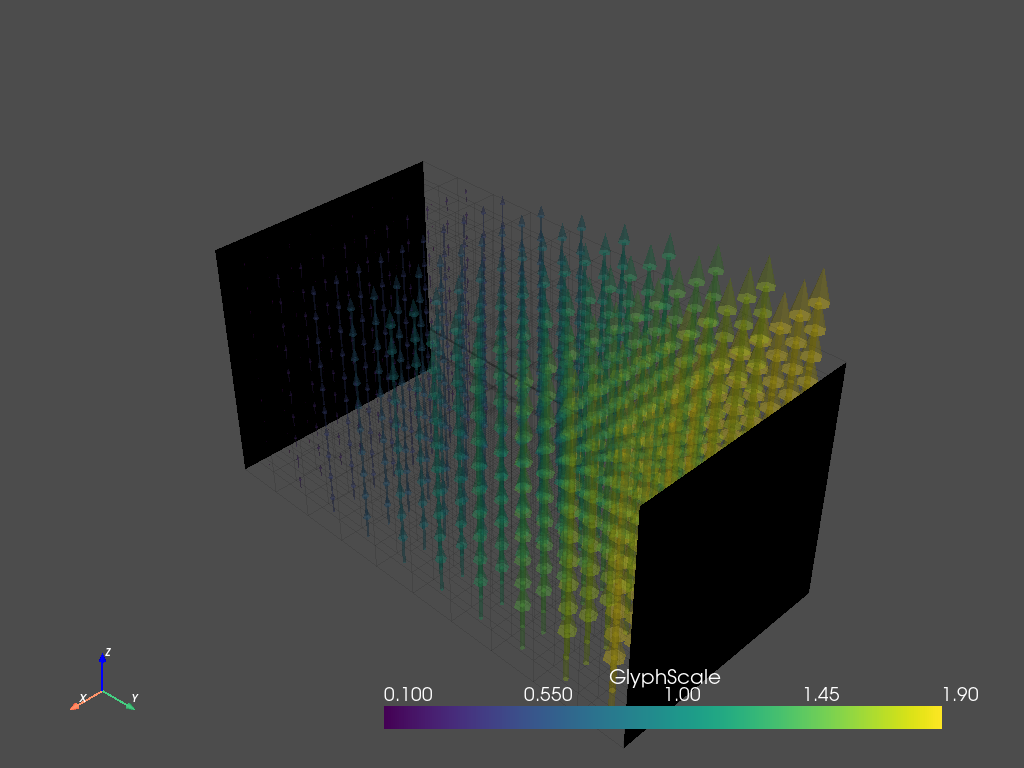

In [7]:
pv.set_jupyter_backend("static")
glyphs = grid.glyph(orient="U", scale="U", factor=0.2)
pv.set_jupyter_backend("static")
p = pv.Plotter()
p.add_mesh(glyphs,opacity=0.3)
p.add_mesh(lowerwall,color="black")
p.add_mesh(grid.extract_all_edges(),color="black",show_edges=True,opacity=0.1)
p.add_mesh(upperwall,color="black")
p.add_axes()
p.show()

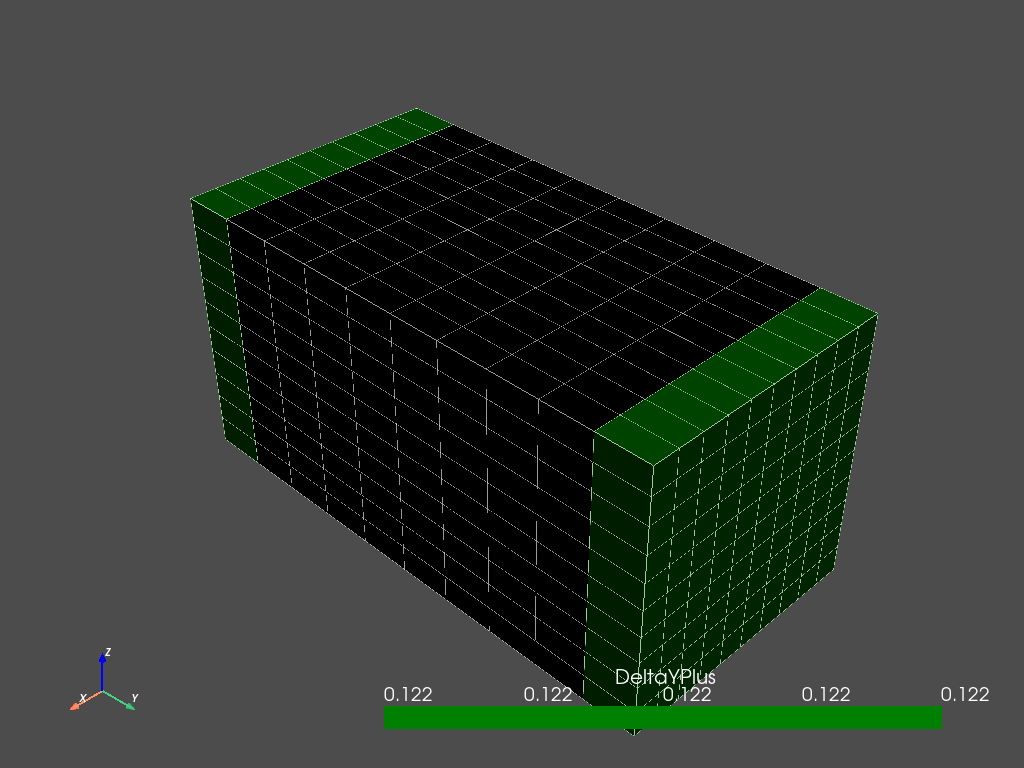

In [8]:
pv.set_jupyter_backend("static")
p = pv.Plotter()
p.add_mesh(dimless_gridspacings,scalars="DeltaYPlus",opacity=0.6,cmap=["green"])
p.add_mesh(dimless_gridspacings.extract_all_edges(),color="green")
p.add_mesh(lowerwall,color="black")
p.add_mesh(grid.extract_all_edges(),color="white",show_edges=True,opacity=0.6)
p.add_mesh(grid,color="black")
p.add_mesh(upperwall,color="black")
p.add_axes()
p.show()

In [9]:
print(f'DeltaXPlus: {round(np.mean(dimless_gridspacings["DeltaXPlus"]),2)}')
print(f'DeltaYPlus: {round(np.mean(dimless_gridspacings["DeltaYPlus"]),2)}')
print(f'DeltaZPlus: {round(np.mean(dimless_gridspacings["DeltaZPlus"]),2)}')

DeltaXPlus: 0.06
DeltaYPlus: 0.12
DeltaZPlus: 0.06


We can also compute the yPlus values.
The method works similiar to the nondimensional gridspacing computation.

Note:

The algorithm assumes a cell centered solver for the flow solution.
The yPlus value needs to be half the size of the DeltaYPlus values.

In [10]:
from ntrfc.meshquality.nondimensionals import calc_dimensionless_yplus
yplus = calc_dimensionless_yplus(grid, [lowerwall, upperwall], "U", "rho", mu_0)

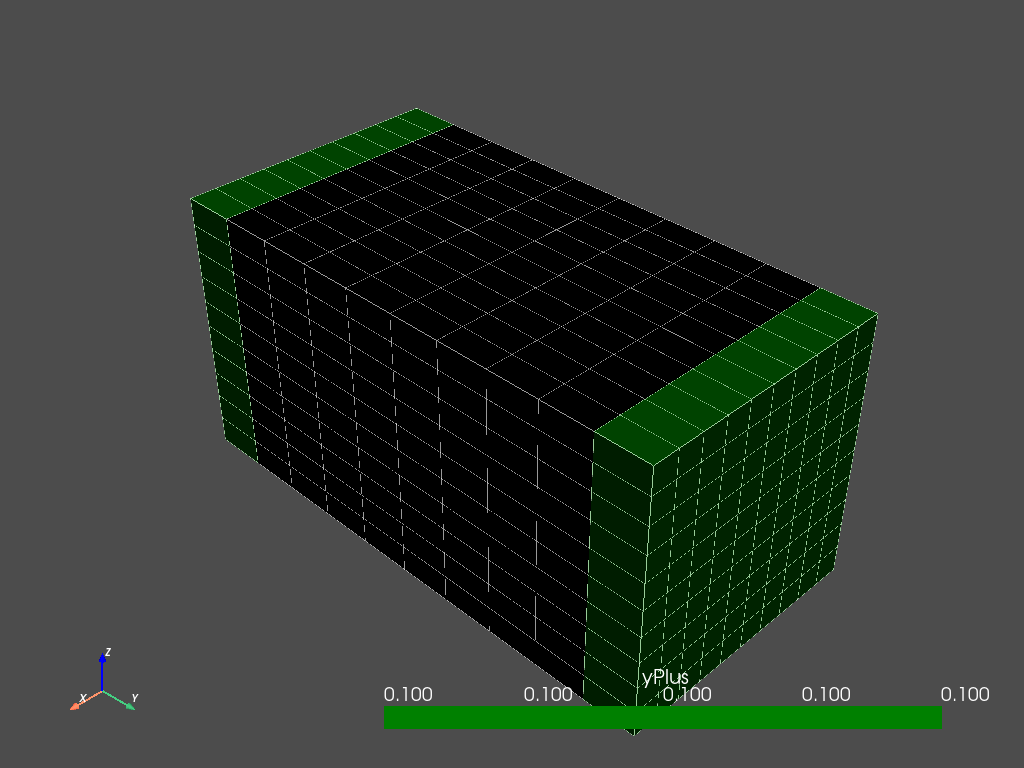

In [11]:
pv.set_jupyter_backend("static")
p = pv.Plotter()
p.add_mesh(yplus,scalars="yPlus",opacity=0.6,cmap=["green"])
p.add_mesh(yplus.extract_all_edges(),color="green")
p.add_mesh(lowerwall,color="black")
p.add_mesh(grid.extract_all_edges(),color="white",show_edges=True,opacity=0.6)
p.add_mesh(grid,color="black")
p.add_mesh(upperwall,color="black")
p.add_axes()
p.show()
